**Final Capstone Project**

**IIT Ropar**

**IIM Amritsar**

**Group Members: Bhavin, Georgy, Prabhujeet, Shrenik**

**Guide: Prof. Puneet Pasricha (IIT Ropar)**

**Value at Risk (VaR) Estimation using the Historical method for Nifty50 data**

## How to read this notebook

Method note: `Historical.md`. The report's result for this method is an **AE ratio of about 3.4** at the 99% level.

The book is ₹1 crore invested in the Nifty 50 on the first date, with the number of units held fixed. `Loss` is the daily change in portfolio value (negative means a loss). On each 501-day block the 99% VaR is the empirical 1% quantile of those changes, which the report identifies with the 5th worst loss in 500 scenarios.

Test blocks are 51 rows and the start date advances by one day, so neighbouring test blocks overlap. The Kupiec and Christoffersen statistics at the bottom are computed on that stacked, overlapping series. Quote the report's AE ratio of about 3.4 as the study result.

Coverage tests, in the form used here:

- **Kupiec (unconditional coverage):** is the breach rate equal to 1%?
- **Christoffersen (independence):** do breaches cluster on consecutive days?
- **Conditional coverage:** both questions together (the two likelihood ratios are added).


In [21]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)


E:\MSDSM\Sem-4\FCP\Historical


In [22]:
# Data, plots, and the chi-square distribution used by the coverage tests.
# yfinance is not required: the sample is the local workbook.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import seaborn as sns
from scipy.stats import chi2
import scipy.stats as stats


In [23]:
# Dates, NIFTY Index. Portfolio value is added in the next cell.
# Sample in the report: 4 January 2005 to 25 September 2023.

nifty_df = pd.read_excel(NIFTY_PATH)  # data/Nifty50_data.xlsx


In [24]:
# ₹1 crore notional on day 1. Units = 1e7 / first index level, then held fixed.
# Portfolio value on day t = units * Nifty level on day t.

# Define the initial portfolio value and calculate the number of shares purchased
initial_investment = 10000000

shares_held = initial_investment/nifty_df['NIFTY Index'].iloc[0]
# Calculate the portfolio value based on the number of shares held
nifty_df['Portfolio Value'] = shares_held * nifty_df['NIFTY Index']


In [25]:
# First estimation window: 501 index levels -> 500 daily portfolio changes.

nifty_df.head()
nf_train = nifty_df[['Dates', 'NIFTY Index', 'Portfolio Value']].iloc[0:501]


In [26]:
# Loss = change in portfolio value. The first row is NaN because of the difference.

# Calculate daily returns
nf_train['Loss'] = nf_train['Portfolio Value'].diff() # Calculate the daily loss
nf_train.head()


,Dates,NIFTY Index,Portfolio Value,Loss
0,2005-01-04,2103.75,1.000000e+07,NaN
1,2005-01-05,2032.20,9.659893e+06,-340106.951872
2,2005-01-06,1998.35,9.498990e+06,-160903.149138
3,2005-01-07,2015.50,9.580511e+06,81521.093286
4,2005-01-10,1982.00,9.421272e+06,-159239.453357


In [27]:
# Confirm the window before sorting. VaR is read from this empirical distribution.

nf_train.head()


,Dates,NIFTY Index,Portfolio Value,Loss
0,2005-01-04,2103.75,1.000000e+07,NaN
1,2005-01-05,2032.20,9.659893e+06,-340106.951872
2,2005-01-06,1998.35,9.498990e+06,-160903.149138
3,2005-01-07,2015.50,9.580511e+06,81521.093286
4,2005-01-10,1982.00,9.421272e+06,-159239.453357


In [28]:
# Sort losses from worst (most negative) to best.
# losses[4] is the 5th worst outcome: the report's 99% VaR on 500 scenarios.
# Printed as a positive rupee amount.

losses = nf_train['Loss'].dropna().tolist()
losses.sort() # Sort the losses in ascending order that is from the highest loss to the lowest loss
print(losses)

# The fifth highest loss is the 99% VaR for a 500-day scenario
VaR_99 = losses[4] # The fifth highest loss

print(f"The 1-day VaR at 99% confidence level is : ${abs(VaR_99):.2f}")


[-1170291.146761734, -786928.1045751646, -699227.5698158052, -674985.1455733813, -646939.9881164581, -550445.6327985711, -543077.837195484, -539750.4456327967, -517171.7171717193, -500534.75935828686, -472964.9435531795, -467973.8562091496, -431610.21984551474, -425193.1075460501, -409982.1746880561, -398336.3042186573, -382887.70053476095, -377183.60071301274, -371004.1592394542, -365300.05941770785, -355080.2139037419, -340106.95187165774, -328698.75222816505, -314200.8318478912, -310160.4278074857, -289483.06595365517, -266666.66666666605, -265002.97088532336, -264289.95840760507, -264289.95840760507, -262626.2626262624, -257872.84610813856, -252881.7587641105, -251455.73380867578, -248366.01307189465, -242424.2424242422, -232442.0677361861, -231966.72608437203, -226500.29708853364, -224123.58882947266, -218894.83065953664, -218419.4890077263, -216755.79322638176, -198455.13963161036, -193464.05228758045, -190612.00237670727, -186809.2691622097, -184432.5609031506, -182768.865121806

In [29]:
# Same 99% threshold written as a quantile. sig = 0.01 is the tail probability.
# For 500 losses, int(500 * 0.01) = 5, and the code takes index 4 (the 5th point).

sig=0.01

index_after_xth = int(len(losses) * sig)
print(f"Index after the {int(100-sig*100)}th percentile: {index_after_xth}")

# Retrieve the loss at this index as the VaR value
VaR_x = (losses[index_after_xth-1])

print(f"The 1-day VaR at {int(100-sig*100)}% confidence level is : ${abs(VaR_x):.2f}")


Index after the 99th percentile: 5
The 1-day VaR at 99% confidence level is : $646939.99


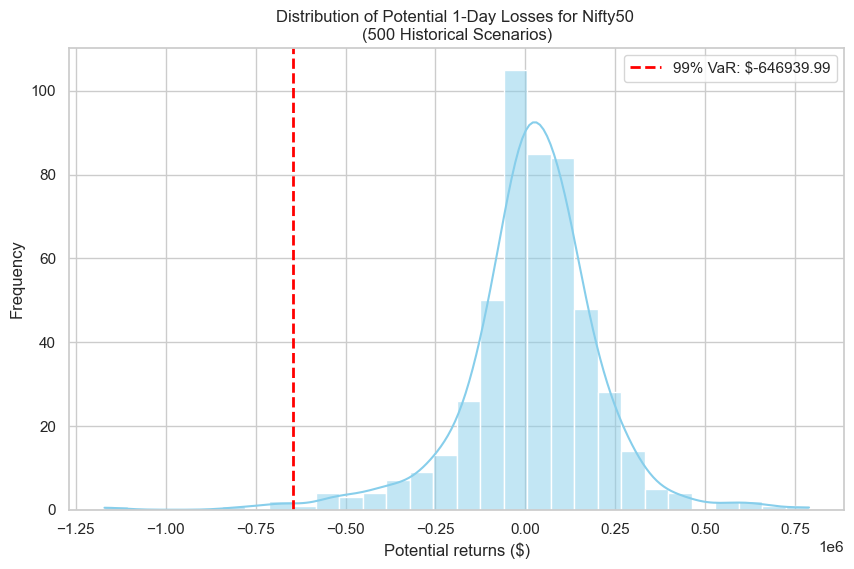

In [30]:
# Histogram of the first window. The vertical line is the 99% historical VaR.

# Plotting the histogram
plt.figure(figsize=(10, 6))
sns.histplot(nf_train['Loss'], bins=30, kde=True, color='skyblue')

# Mark the VaR threshold on the histogram
plt.axvline(VaR_x, color='red', linestyle='--', linewidth=2, label=f'{int(100-sig*100)}% VaR: ${VaR_x:.2f}')

# Add labels and title
plt.title("Distribution of Potential 1-Day Losses for Nifty50 \n(500 Historical Scenarios)")
plt.xlabel("Potential returns ($)")
plt.ylabel("Frequency")
plt.legend()

# Show plot
plt.show()


In [31]:
# First out-of-sample block: the 51 rows after the opening window.
# One row is lost to diff(), so about 50 scored days.

nf_test=nifty_df[['Dates','NIFTY Index','Portfolio Value']].iloc[501:550]

# Calculate daily returns
nf_test['Loss'] = nf_test['Portfolio Value'].diff() # Calculate the daily loss
nf_test.head()


,Dates,NIFTY Index,Portfolio Value,Loss
501,2006-12-06,4015.95,1.908948e+07,NaN
502,2006-12-07,4015.35,1.908663e+07,-2852.049911
503,2006-12-08,3962.00,1.883304e+07,-253594.771242
504,2006-12-11,3849.50,1.829828e+07,-534759.358289
505,2006-12-12,3716.90,1.766797e+07,-630303.030303


In [32]:
# Count test days whose portfolio change is worse than the training-window VaR.
# The screen test compares the count with sig * 100 (one breach per 100 days at 99%).

exceeded_VaR = nf_test[nf_test['Loss'] < VaR_x]
num_violations = len(exceeded_VaR)

# Check if the number of violations is within the expected limit for X% confidence
if num_violations > sig*100:
    print(f"The historical method does not hold with {int(100-sig*100)}% confidence.")
else:
    print(f"The historical method holds with {int(100-sig*100)}% confidence.")
print(f"Number of days where loss exceeded Value at Risk (VaR): {num_violations}")


The historical method holds with 99% confidence.
Number of days where loss exceeded Value at Risk (VaR): 0


In [33]:
# One training frame per start date. Each frame is 501 rows and carries its own Loss column.
# Frame i uses rows [i, i+501). The loop later pairs frame i with test frame i.

# Automating for all windows of 501 days for training data
train_dfs = [
    nifty_df.iloc[i:i+501][['Dates', 'NIFTY Index', 'Portfolio Value']].assign(
        Loss=lambda df: df['Portfolio Value'].diff()
    )
    for i in range(len(nifty_df) - 501)
]

# Example: Accessing the first training set
train_dfs[1].head()


,Dates,NIFTY Index,Portfolio Value,Loss
1,2005-01-05,2032.20,9.659893e+06,NaN
2,2005-01-06,1998.35,9.498990e+06,-160903.149138
3,2005-01-07,2015.50,9.580511e+06,81521.093286
4,2005-01-10,1982.00,9.421272e+06,-159239.453357
5,2005-01-11,1952.05,9.278907e+06,-142364.824718


In [34]:
# Test frames start at row 501 and are 51 rows long.
# The start index advances by 1, so consecutive tests share 50 of 51 rows.
# Coverage tests below stack these overlapping days.

# Automating for all windows of 501 days for training data
test_dfs = [
    nifty_df.iloc[i:i+51][['Dates', 'NIFTY Index', 'Portfolio Value']].assign(
        Loss=lambda df: df['Portfolio Value'].diff()
    )
    for i in range(501,len(nifty_df))
]

# Example: Accessing the first training set
test_dfs[1].head()


,Dates,NIFTY Index,Portfolio Value,Loss
502,2006-12-07,4015.35,1.908663e+07,NaN
503,2006-12-08,3962.00,1.883304e+07,-253594.771242
504,2006-12-11,3849.50,1.829828e+07,-534759.358289
505,2006-12-12,3716.90,1.766797e+07,-630303.030303
506,2006-12-13,3765.20,1.789756e+07,229590.017825


In [35]:
# train_dfs and test_dfs have the same length: one pair per start date.

len(train_dfs), len(test_dfs)


(4388, 4388)

In [36]:
# Three standard VaR backtests.
# Kupiec: breach frequency versus sig.
# Christoffersen: probability of a breach given yesterday was a breach,
# versus the probability given yesterday was calm.
# Conditional coverage: sum of the two likelihood-ratio statistics, df = 2.
# A large p-value means that test does not reject its null.

import numpy as np
import scipy.stats as stats

# Function to perform Kupiec's Proportion of Failures (POF) Test
def kupiec_pof_test(num_violations, total_days, sig):
    if num_violations == 0 or num_violations == total_days:
        return np.nan, np.nan  # Avoid undefined log probabilities
    
    expected_p = 1 - sig  # Expected violation probability
    observed_p = num_violations / total_days
    
    epsilon = 1e-10  # Small value to prevent log(0)
    likelihood_ratio = -2 * (
        np.log(max((1 - expected_p) ** (total_days - num_violations) * expected_p ** num_violations, epsilon))
        - np.log(max((1 - observed_p) ** (total_days - num_violations) * observed_p ** num_violations, epsilon))
    )
    p_value = 1 - stats.chi2.cdf(likelihood_ratio, df=1)
    
    return likelihood_ratio, p_value

# Function to perform Christoffersen's Independence Test
def christoffersen_independence_test(violations):
    T00 = T01 = T10 = T11 = 0
    for i in range(1, len(violations)):
        if violations[i - 1] == 0 and violations[i] == 0:
            T00 += 1
        elif violations[i - 1] == 0 and violations[i] == 1:
            T01 += 1
        elif violations[i - 1] == 1 and violations[i] == 0:
            T10 += 1
        elif violations[i - 1] == 1 and violations[i] == 1:
            T11 += 1

    if (T00 + T01) == 0 or (T10 + T11) == 0:
        return np.nan, np.nan  # Avoid division by zero

    p_0 = (T00 + T01) / (T00 + T01 + T10 + T11)
    p_1 = (T10 + T11) / (T00 + T01 + T10 + T11)
    p_01 = max(T01 / (T00 + T01), 1e-10)  # Prevent log(0)
    p_11 = max(T11 / (T10 + T11), 1e-10)  # Prevent log(0)

    likelihood_ratio = -2 * (
        np.log(max((1 - p_0) ** T00 * p_0 ** T01 * (1 - p_1) ** T10 * p_1 ** T11, 1e-10))
        - np.log(max((1 - p_01) ** T00 * p_01 ** T01 * (1 - p_11) ** T10 * p_11 ** T11, 1e-10))
    )
    p_value = 1 - stats.chi2.cdf(likelihood_ratio, df=1)

    return likelihood_ratio, p_value

# Function to perform Conditional Coverage Test
def christoffersen_conditional_coverage_test(pof_lrt, ind_lrt):
    if np.isnan(pof_lrt) or np.isnan(ind_lrt):
        return np.nan, np.nan  # Handle undefined cases
    cc_lrt = pof_lrt + ind_lrt
    p_value = 1 - stats.chi2.cdf(cc_lrt, df=2)
    return cc_lrt, p_value


501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501
501


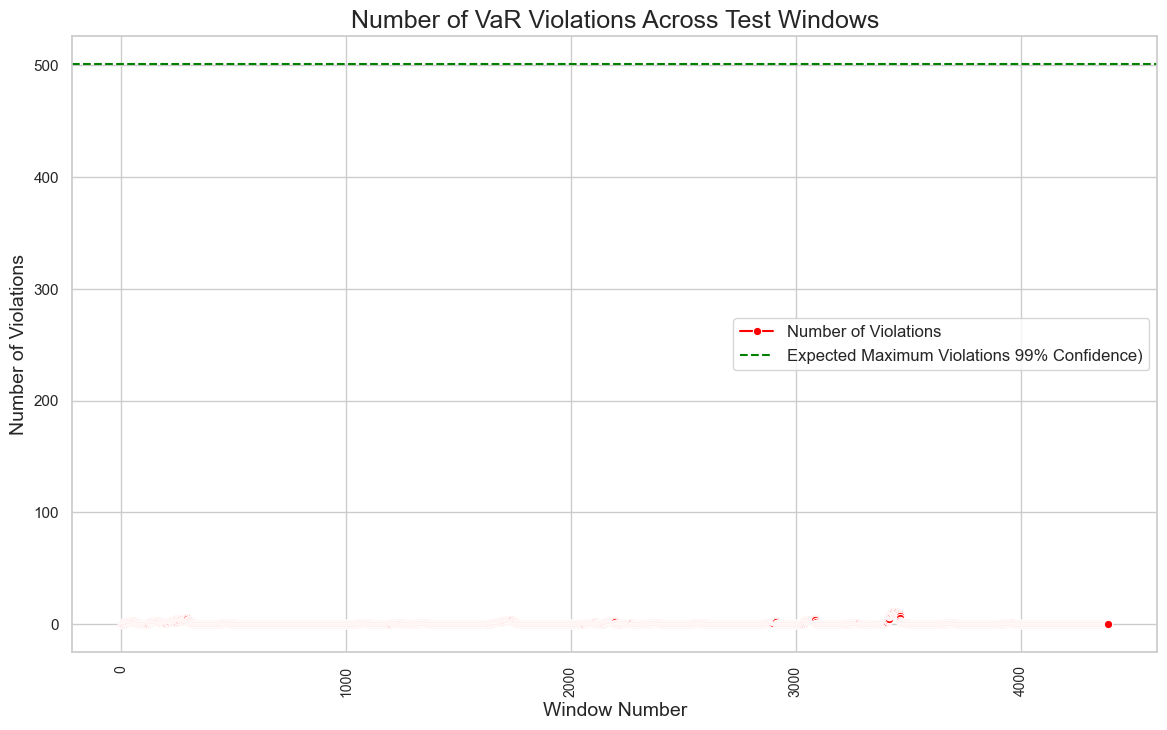

In [ ]:
# Roll the 99% historical VaR and record breaches in every test frame.
# The chart shows breaches per window. The horizontal line is the count
# the 99% level would allow inside one window (sig * number of training losses).

total_violations = 0
violated_windows = []
violations_mapping = {}  # To track which windows have violations
all_violations = []  # Store all binary violations for independence test
total_days = sum(len(test_dfs[i]) for i in range(len(test_dfs)))  # Total test days


for i in range(len(train_dfs)):
    losses = train_dfs[i]['Loss'].tolist()
    losses.sort()
    index_after_xth = int(len(losses) * sig)
    VaR_x = losses[index_after_xth - 1]

    # Identify violations in the test data
    exceeded_VaR = test_dfs[i][test_dfs[i]['Loss'] < VaR_x]
    num_violations = len(exceeded_VaR)

    if num_violations > 0:
        violated_windows.append(num_violations)
        violations_mapping[i + 1] = num_violations
        total_violations += num_violations
        #print(f"Window {i + 1}: Number of days where loss exceeded Value at Risk (VaR): {num_violations}")
    else:
        violations_mapping[i + 1] = 0  # Mark no violations for this window
    # Binary sequence of violations for independence test
    all_violations.extend((test_dfs[i]['Loss'] < VaR_x).astype(int).tolist())

# Summary of total violations
print(f"\nOut of all samples, {total_violations} violations were observed.")
window_numbers = list(violations_mapping.keys())
violations_count = list(violations_mapping.values())

# Set Seaborn style
sns.set(style="whitegrid")

plt.figure(figsize=(14, 8))
sns.lineplot(
    x=window_numbers,
    y=violations_count,
    marker='o',
    color='red',
    label='Number of Violations'
)

# Add horizontal reference line for expected violations
plt.axhline(int(sig*len(losses)), color='green', linestyle='--', label=f'Expected Maximum Violations {int(100-sig*100)}% Confidence)')

plt.title('Number of VaR Violations Across Test Windows', fontsize=18)
plt.xlabel('Window Number', fontsize=14)
plt.ylabel('Number of Violations', fontsize=14)
plt.legend(fontsize=12)
plt.xticks(fontsize=10, rotation=90)  # Set x-ticks vertically
plt.grid(True)
plt.show()


In [38]:
# Unconditional coverage, independence, and conditional coverage
# on the stacked violation series from the cell above.
# The report quotes p-values of about 0.998 for these three tests,
# together with an AE ratio of about 3.4.

# Perform Unconditional Coverage Test (Kupiec's POF Test)
pof_lrt, pof_pval = kupiec_pof_test(total_violations, total_days, sig)
print(f"Kupiec's POF Test: LR Statistic = {pof_lrt:.4f}, p-value = {pof_pval:.4f}")

# Perform Independence Test (Christoffersen's Test)
ind_lrt, ind_pval = christoffersen_independence_test(all_violations)
print(f"Christoffersen's Independence Test: LR Statistic = {ind_lrt:.4f}, p-value = {ind_pval:.4f}")

# Perform Conditional Coverage Test
cc_lrt, cc_pval = christoffersen_conditional_coverage_test(pof_lrt, ind_lrt)
print(f"Christoffersen's Conditional Coverage Test: LR Statistic = {cc_lrt:.4f}, p-value = {cc_pval:.4f}")


Kupiec's POF Test: LR Statistic = -0.0000, p-value = 1.0000
Christoffersen's Independence Test: LR Statistic = -0.0000, p-value = 1.0000
Christoffersen's Conditional Coverage Test: LR Statistic = -0.0000, p-value = 1.0000



Out of all samples, 2573 violations were observed.


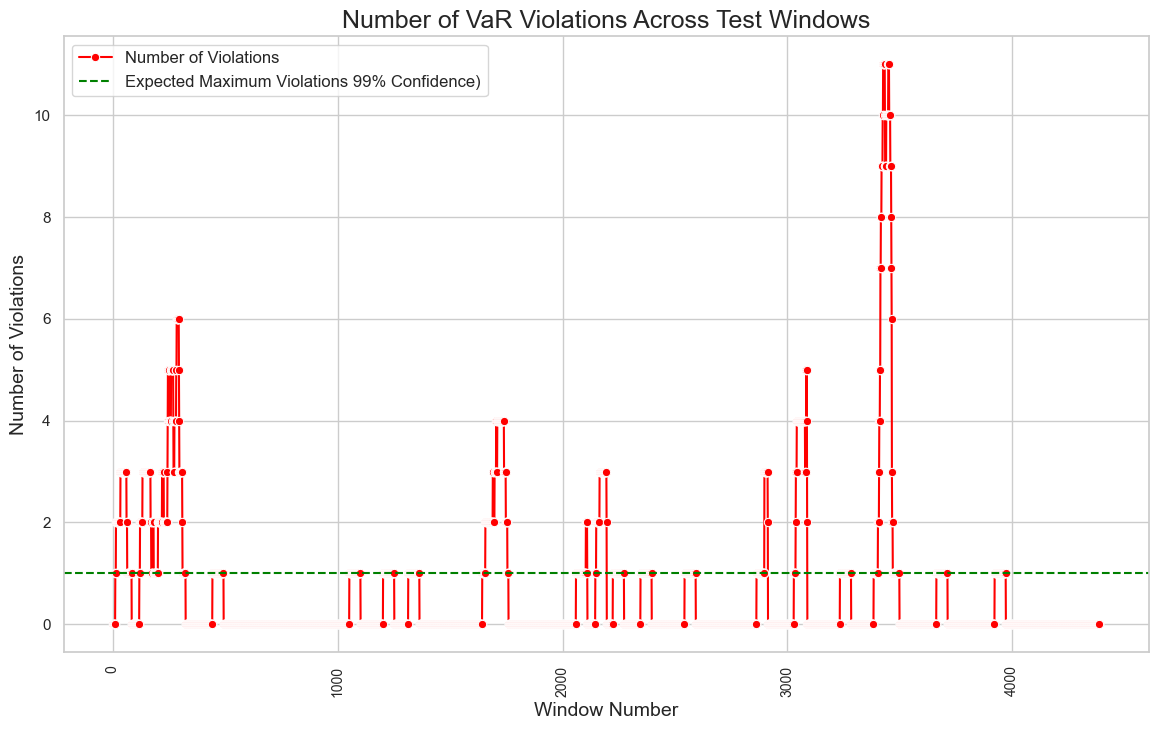

In [39]:
# Repeat of the rolling count. sig_one is assigned and is not used;
# the quantile still uses sig from the earlier cell (0.01, i.e. 99% VaR).
# The reference line here is sig * 100, i.e. 1 expected breach on the chart scale.

total_violations = 0
violated_windows = []
violations_mapping = {}  # To track which windows have violations
all_violations = []  # Store all binary violations for independence test
total_days = sum(len(test_dfs[i]) for i in range(len(test_dfs)))  # Total test days

sig_one = 0.01
for i in range(len(train_dfs)):
    losses = train_dfs[i]['Loss'].tolist()
    losses.sort() 
    index_after_xth = int(len(losses) * sig)
    VaR_x = losses[index_after_xth - 1]

    # Identify violations in the test data
    exceeded_VaR = test_dfs[i][test_dfs[i]['Loss'] < VaR_x]
    num_violations = len(exceeded_VaR)

    if num_violations > 0:
        violated_windows.append(num_violations)
        violations_mapping[i + 1] = num_violations
        total_violations += num_violations
        #print(f"Window {i + 1}: Number of days where loss exceeded Value at Risk (VaR): {num_violations}")
    else:
        violations_mapping[i + 1] = 0  # Mark no violations for this window
    # Binary sequence of violations for independence test
    all_violations.extend((test_dfs[i]['Loss'] < VaR_x).astype(int).tolist())

# Summary of total violations
print(f"\nOut of all samples, {total_violations} violations were observed.")
window_numbers = list(violations_mapping.keys())
violations_count = list(violations_mapping.values())

# Set Seaborn style
sns.set(style="whitegrid")

plt.figure(figsize=(14, 8))
sns.lineplot(
    x=window_numbers,
    y=violations_count,
    marker='o',
    color='red',
    label='Number of Violations'
)

# Add horizontal reference line for expected violations
plt.axhline(sig*100, color='green', linestyle='--', label=f'Expected Maximum Violations {int(100-sig*100)}% Confidence)')

plt.title('Number of VaR Violations Across Test Windows', fontsize=18)
plt.xlabel('Window Number', fontsize=14)
plt.ylabel('Number of Violations', fontsize=14)
plt.legend(fontsize=12)
plt.xticks(fontsize=10, rotation=90)  # Set x-ticks vertically
plt.grid(True)
plt.show()
